In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

train = pd.read_csv('train_clean.csv')
y = train['Item_Outlet_Sales']

print(train.shape)
train.head()

(8523, 18)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,is_train,Item_Category,Outlet_Age,Price_per_Weight,Base_Price,units
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,1,FD,14,26.861204,249.0092,15.0
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,1,DR,4,8.153581,49.2692,9.0
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,1,FD,14,8.092457,139.8180,15.0
3,FDX07,19.20,Regular,0.022930,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,1,FD,15,9.484115,183.0950,4.0
4,NCD19,8.93,Non-Edible,0.014670,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,1,NC,26,6.031512,55.2614,18.0


In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# a dictionary to collect all the scores
scores = {}
# and one to keep each model's predictions
predictions = {}

## Model 0: baseline


In [ ]:
guess = np.zeros(len(train))

for train_rows, valid_rows in kfold.split(train):
    guess[valid_rows] = y.iloc[train_rows].mean()

scores['Overall average'] = np.sqrt(mean_squared_error(y, guess))
print('RMSE:', round(scores['Overall average'], 2))

RMSE: 1707.01


## Model 1: average sales of each store

In [ ]:
guess = np.zeros(len(train))

for train_rows, valid_rows in kfold.split(train):
    part_train = train.iloc[train_rows]
    part_valid = train.iloc[valid_rows]

    store_average = part_train.groupby('Outlet_Identifier')['Item_Outlet_Sales'].mean()
    guess[valid_rows] = part_valid['Outlet_Identifier'].map(store_average).values

scores['Store average'] = np.sqrt(mean_squared_error(y, guess))
print('RMSE:', round(scores['Store average'], 2))

RMSE: 1488.8


## Model 2: Linear Regression



In [ ]:
word_columns = ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size',
                'Outlet_Location_Type', 'Outlet_Type', 'Item_Category']

number_columns = ['Base_Price', 'Item_MRP', 'Item_Weight', 'Item_Visibility',
                  'Outlet_Age', 'Price_per_Weight']

X = train[word_columns + number_columns]
X = pd.get_dummies(X, columns=word_columns)

print('X shape:', X.shape)

X shape: (8523, 48)


In [ ]:
model = LinearRegression()
guess = cross_val_predict(model, X, y, cv=kfold)

scores['Linear Regression'] = np.sqrt(mean_squared_error(y, guess))
predictions['Linear Regression'] = guess
print('RMSE:', round(scores['Linear Regression'], 2))

RMSE: 1132.15


## Model 3: Decision Tree



In [ ]:
model = DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=42)
guess = cross_val_predict(model, X, y, cv=kfold)

scores['Decision Tree'] = np.sqrt(mean_squared_error(y, guess))
predictions['Decision Tree'] = guess
print('RMSE:', round(scores['Decision Tree'], 2))

RMSE: 1087.8


In [ ]:
model = DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=42)
model.fit(X, y)

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance.head(8).round(3))

Item_MRP                         0.407
Outlet_Type_Grocery Store        0.325
Base_Price                       0.141
Outlet_Identifier_OUT027         0.098
Outlet_Type_Supermarket Type3    0.022
Outlet_Age                       0.007
Item_Weight                      0.000
Price_per_Weight                 0.000
dtype: float64


## Model 4: Random Forest

A random forest is many decision trees, and it averages their answers.

In [ ]:
model = RandomForestRegressor(n_estimators=200, max_depth=6, min_samples_leaf=30,
                              random_state=42, n_jobs=-1)
guess = cross_val_predict(model, X, y, cv=kfold)

scores['Random Forest'] = np.sqrt(mean_squared_error(y, guess))
predictions['Random Forest'] = guess
print('RMSE:', round(scores['Random Forest'], 2))

RMSE: 1080.91


Overall average                   1707.01
Store average                     1488.80
Linear Regression                 1132.15
Decision Tree                     1087.80
Random Forest                     1080.91
Price x store rate (noisy MRP)    1071.97
Price x store rate                1071.51


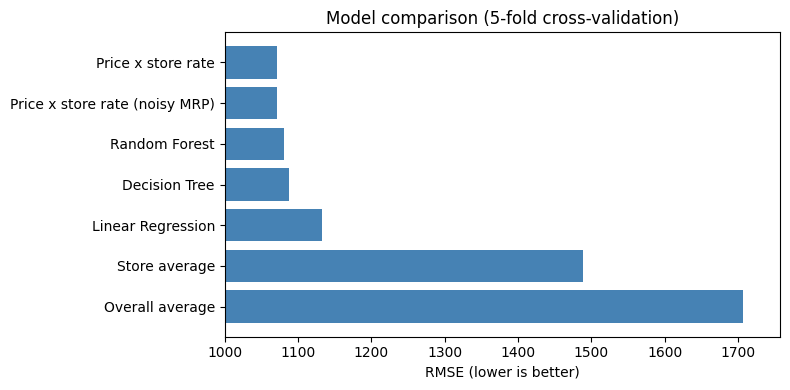

In [ ]:
table = pd.Series(scores).sort_values(ascending=False)
print(table.round(2).to_string())

plt.figure(figsize=(8, 4))
plt.barh(table.index, table.values, color='steelblue')
plt.xlim(1000, table.max() + 50)
plt.xlabel('RMSE (lower is better)')
plt.title('Model comparison (5-fold cross-validation)')
plt.tight_layout()
plt.show()

In [ ]:
for weight in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    mix = weight * predictions['Price x store rate'] + (1 - weight) * predictions['Random Forest']
    rmse = np.sqrt(mean_squared_error(y, mix))
    print('weight on my rule =', weight, '| RMSE =', round(rmse, 2))

weight on my rule = 1.0 | RMSE = 1071.51
weight on my rule = 0.9 | RMSE = 1071.46
weight on my rule = 0.8 | RMSE = 1071.63
weight on my rule = 0.7 | RMSE = 1072.03
weight on my rule = 0.6 | RMSE = 1072.64
weight on my rule = 0.5 | RMSE = 1073.47


In [ ]:
units_all = train['Item_Outlet_Sales'] / train['Base_Price']
perfect_rate = units_all.groupby(train['Outlet_Identifier']).transform('mean')
perfect_guess = train['Base_Price'] * perfect_rate

floor = np.sqrt(mean_squared_error(y, perfect_guess))
mix = 0.7 * predictions['Price x store rate'] + 0.3 * predictions['Random Forest']
blend_score = np.sqrt(mean_squared_error(y, mix))

print('best possible for this kind of model:', round(floor, 2))
print('my 70/30 blend:                      ', round(blend_score, 2))

best possible for this kind of model: 1070.28
my 70/30 blend:                       1072.03
